In [ ]:
import os
import json
import zipfile
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42
N_JOBS = 2
output_dir = Path("hasil_svm")
output_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=0.95)
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.8.0


In [ ]:
columns = [
    "fLength", "fWidth", "fSize", "fConc", "fConc1",
    "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist", "Class"
]

if not Path("magic04.data").exists() and not list(Path(".").glob("*.zip")):
    from google.colab import files
    files.upload()

if Path("magic04.data").exists():
    data_df = pd.read_csv("magic04.data", header=None, names=columns)
else:
    data_df = None
    for path in Path(".").glob("*.zip"):
        with zipfile.ZipFile(path) as archive:
            members = [name for name in archive.namelist()
                       if Path(name).name == "magic04.data"]
            if members:
                with archive.open(members[0]) as file:
                    data_df = pd.read_csv(file, header=None, names=columns)
                break
    if data_df is None:
        raise FileNotFoundError("Unggah ZIP MAGIC yang berisi magic04.data.")

data_df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,Class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [ ]:
data_df.sample(5, random_state=RANDOM_STATE)

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,Class
18749,48.0573,11.0862,2.9571,0.3620,0.1882,0.4200,32.4358,-2.2992,26.9300,165.2240,h
7051,23.4858,0.0000,2.2393,0.7378,0.3775,-2.9397,13.0915,0.0001,19.3410,235.3420,g
10901,40.5429,19.4073,3.3382,0.2369,0.1269,29.1908,27.0567,-7.1243,10.0643,195.6030,g
15858,16.6123,7.8423,2.5572,0.5829,0.3371,6.7271,-10.3448,-2.3240,14.5111,214.2655,h
17968,205.4250,37.7936,3.2727,0.2167,0.1257,46.0952,-210.9350,-29.7478,60.0580,206.1730,h


In [ ]:
data_df.info()
print("Ukuran data:", data_df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  Class     19020 non-null  object 
dtypes: float64(10), object(1)
memory usage: 1.6+ MB
Ukuran data: (19020, 11)


In [ ]:
data_df.isnull().sum()

fLength     0
fWidth      0
fSize       0
fConc       0
fConc1      0
fAsym       0
fM3Long     0
fM3Trans    0
fAlpha      0
fDist       0
Class       0
dtype: int64

In [ ]:
data_df.describe()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


In [ ]:
features = columns[:-1]
n_raw = len(data_df)
n_duplicate = int(data_df.duplicated().sum())
print("Baris duplikat:", n_duplicate)
print("Duplikat pada seluruh fitur:", data_df.duplicated(subset=features).sum())
print("Nilai tidak finite:", (~np.isfinite(data_df[features])).sum().sum())

class_raw = data_df["Class"].value_counts().rename("Jumlah").to_frame()
class_raw["Persen"] = 100 * class_raw["Jumlah"] / len(data_df)
class_raw

Baris duplikat: 115
Duplikat pada seluruh fitur: 115
Nilai tidak finite: 0


,Jumlah,Persen
Class,,
g,12332,64.837014
h,6688,35.162986


Data awal berisi 19.020 baris dan 10 fitur numerik. Tidak ada nilai hilang, tetapi terdapat 115 baris duplikat persis. Duplikat dihapus **sebelum** pembagian data supaya salinan observasi yang sama tidak berada di train dan test.

In [ ]:
data_df = data_df.drop_duplicates().reset_index(drop=True)
assert data_df[features].notna().all().all()
assert np.isfinite(data_df[features]).all().all()
assert set(data_df["Class"]) == {"g", "h"}
assert not data_df.duplicated(subset=features).any()

print("Ukuran setelah duplikat dihapus:", data_df.shape)
data_df["Class"].value_counts()

Ukuran setelah duplikat dihapus: (18905, 11)


Class
g    12332
h     6573
Name: count, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

X = data_df.drop(columns="Class")
y = data_df["Class"].map({"h": 0, "g": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

train_df = X_train.copy()
train_df["Class"] = y_train.map({0: "h", 1: "g"})
split_table = pd.DataFrame({
    "Semua (bersih)": y.value_counts(),
    "Train": y_train.value_counts(),
    "Test": y_test.value_counts()
}).rename(index={0: "Hadron", 1: "Gamma"})
split_table.to_csv(output_dir / "pembagian_data.csv")
split_table

,Semua (bersih),Train,Test
Class,,,
Gamma,12332,9866,2466
Hadron,6573,5258,1315


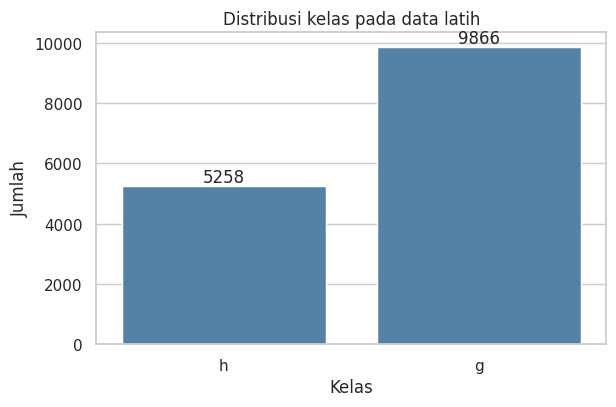

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=train_df, x="Class", order=["h", "g"], color="steelblue", ax=ax)
ax.set(xlabel="Kelas", ylabel="Jumlah", title="Distribusi kelas pada data latih")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(output_dir / "distribusi_kelas.png", dpi=180)
plt.show()

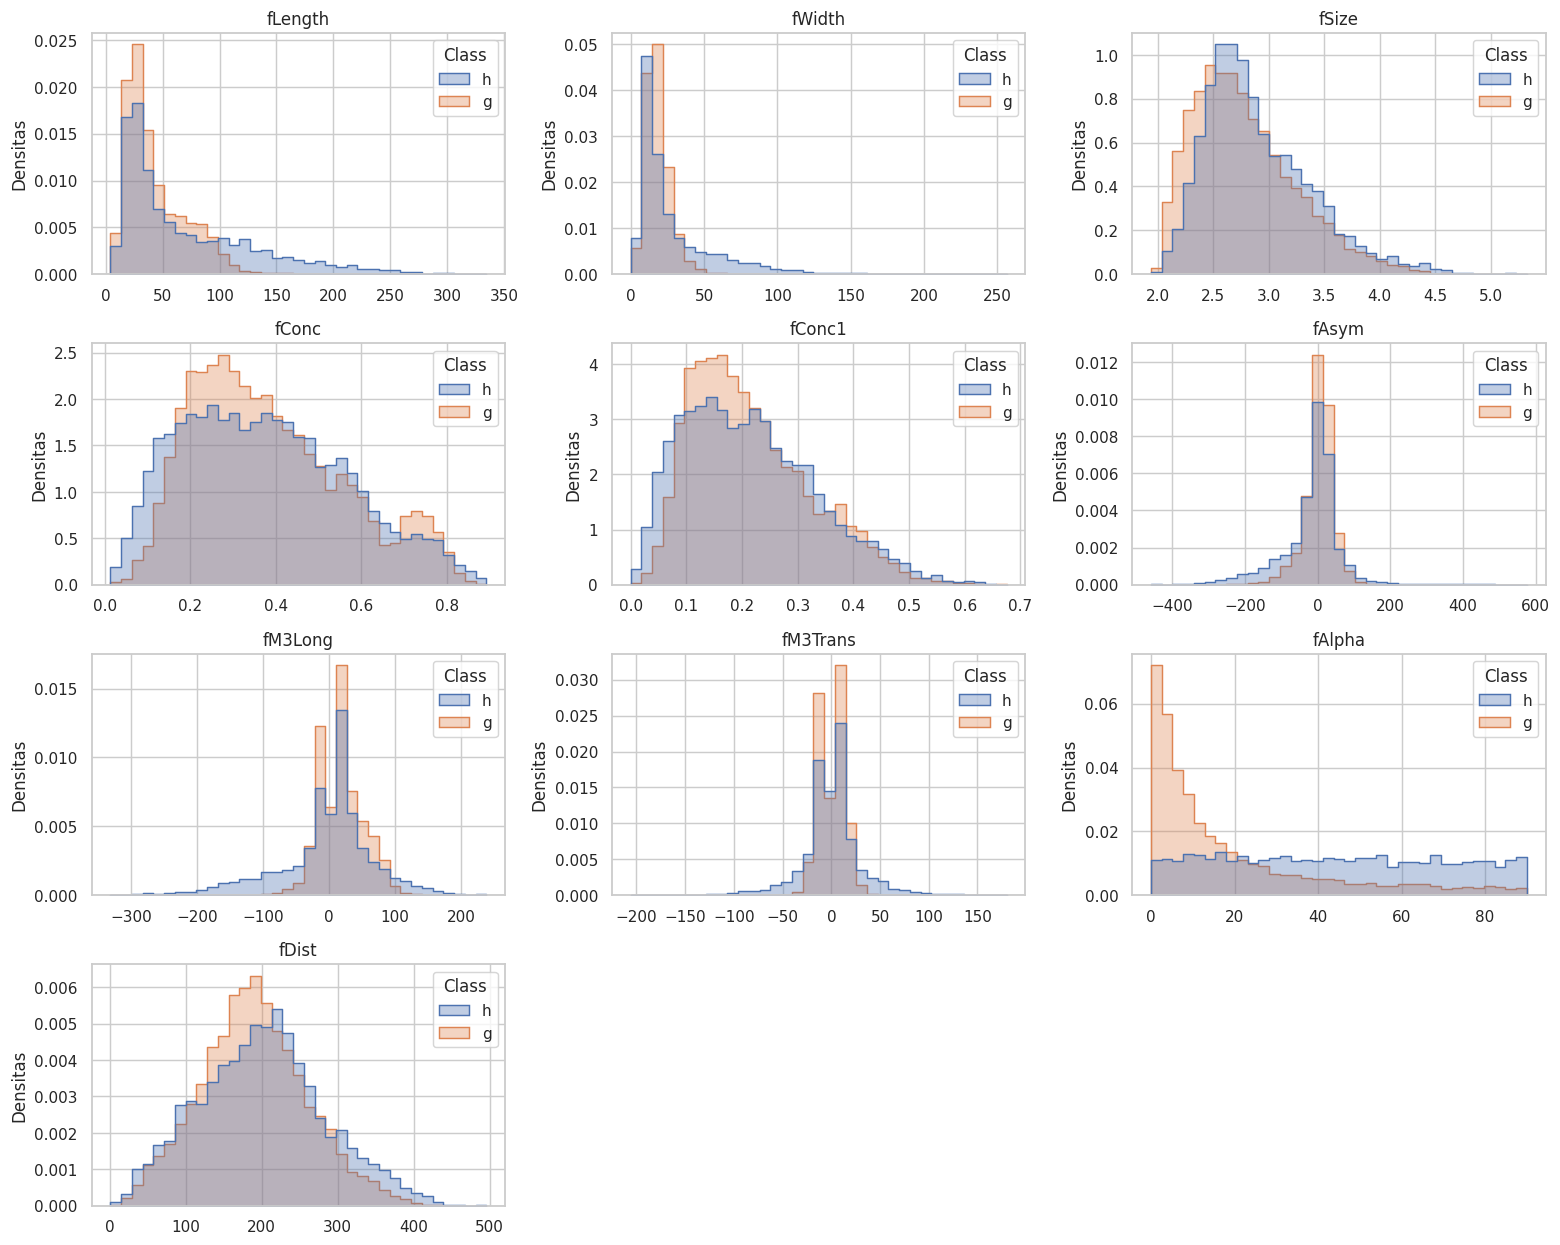

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(
        data=train_df, x=col, hue="Class", hue_order=["h", "g"],
        bins=35, stat="density", common_norm=False,
        element="step", alpha=0.35, ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densitas")

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(output_dir / "histogram_fitur.png", dpi=180)
plt.show()

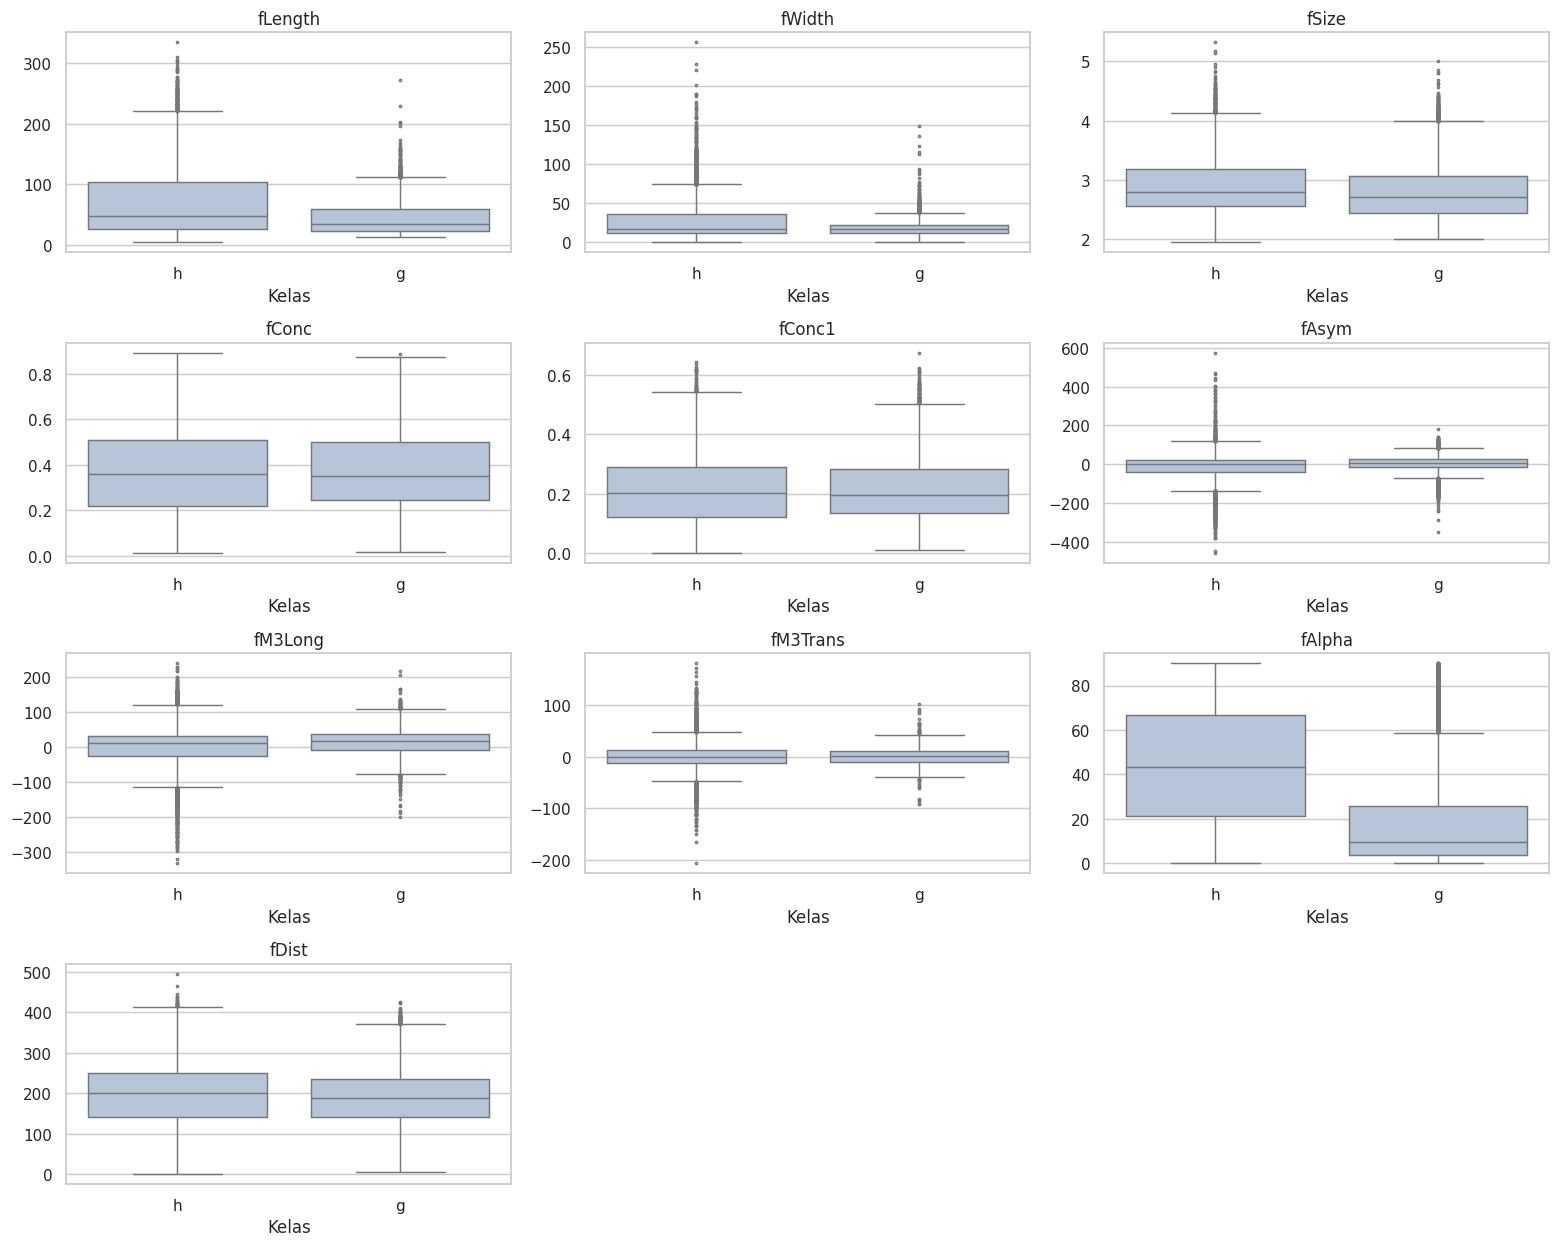

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        data=train_df, x="Class", y=col, order=["h", "g"],
        color="lightsteelblue", fliersize=1.5, ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("Kelas")
    axes[i].set_ylabel("")

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(output_dir / "boxplot_fitur.png", dpi=180)
plt.show()

In [ ]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outlier_mask = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)

feature_summary = pd.DataFrame({
    "Minimum": X_train.min(),
    "Maksimum": X_train.max(),
    "Skewness": X_train.skew(),
    "Median hadron": train_df.groupby("Class")[features].median().loc["h"],
    "Median gamma": train_df.groupby("Class")[features].median().loc["g"],
    "Di luar 1.5 IQR (%)": 100 * outlier_mask.mean()
})
feature_summary.to_csv(output_dir / "ringkasan_fitur.csv")
feature_summary.round(3)

,Minimum,Maksimum,Skewness,Median hadron,Median gamma,Di luar 1.5 IQR (%)
fLength,4.284,334.177,2.042,47.431,34.356,5.177
fWidth,0.000,256.382,3.453,17.387,17.034,8.113
fSize,1.941,5.323,0.865,2.798,2.703,1.865
fConc,0.013,0.893,0.493,0.358,0.353,0.000
fConc1,0.000,0.675,0.689,0.201,0.195,0.793
fAsym,-457.916,575.241,-1.026,-1.173,6.322,9.349
fM3Long,-331.780,238.321,-1.160,10.738,16.747,6.414
fM3Trans,-205.895,179.851,0.056,-0.000,1.035,4.450
fAlpha,0.000,90.000,0.859,43.435,9.784,0.000
fDist,1.283,495.561,0.230,199.832,187.625,0.707


`fLength` dan `fWidth` memiliki ekor panjang ke kanan. Gamma cenderung memiliki `fAlpha` lebih kecil, tetapi tetap ada tumpang tindih antarkelas. Selain itu, `fSize` sudah berbentuk logaritma.  Histogram menggunakan densitas yang dinormalisasi per kelas agar perbedaan jumlah kelas tidak mendominasi perbandingan bentuk distribusi.



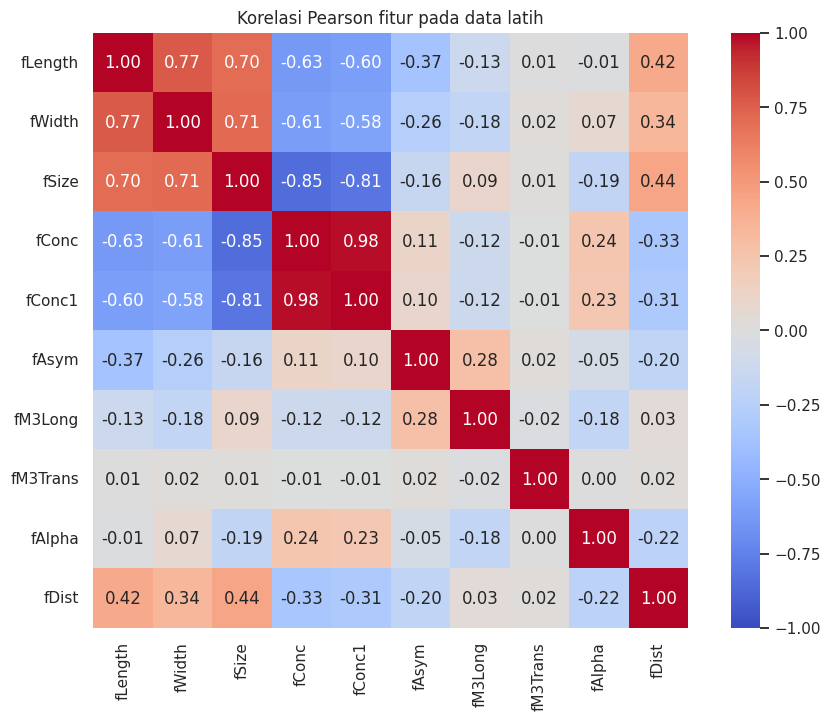

In [ ]:
corr = X_train.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True)
plt.title("Korelasi Pearson fitur pada data latih")
plt.tight_layout()
plt.savefig(output_dir / "korelasi_fitur.png", dpi=180)
plt.show()

`fConc` dan `fConc1` sangat berkorelasi. Korelasi menunjukkan kemiripan informasi antara kedua fitur.

Sepuluh fitur akan dipertahankan daripada menghapus beberapa, seperti pencilan pada boxplot yang dimiliki oleh beberapa fitur. Karena SVM menggunakan kombinasi fitur, penghapusan fitur sebaiknya diuji melalui validasi silang tersendiri.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer, roc_auc_score, accuracy_score, balanced_accuracy_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "pauc": make_scorer(roc_auc_score, response_method="decision_function", max_fpr=0.1),
    "auc": "roc_auc"
}

linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(dual=False, max_iter=20000, random_state=RANDOM_STATE))
])
rbf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", cache_size=256))
])

linear_params = {
    "svm__C": [0.01, 0.1, 1, 10, 100],
    "svm__class_weight": [None, "balanced"]
}
rbf_params = {
    "svm__C": [1, 10, 100],
    "svm__gamma": [0.01, 0.1, 1],
    "svm__class_weight": [None, "balanced"]
}

In [ ]:
grids = {}
search_times = {}

for name, pipeline, params in [
    ("LinearSVC", linear_pipeline, linear_params),
    ("RBF", rbf_pipeline, rbf_params)
]:
    start = perf_counter()
    grid = GridSearchCV(
        pipeline, params,
        cv=cv, scoring=scoring, refit="pauc",
        return_train_score=True, n_jobs=N_JOBS,
        pre_dispatch=N_JOBS, error_score="raise", verbose=1
    )
    grid.fit(X_train, y_train)
    grids[name] = grid
    search_times[name] = perf_counter() - start
    pd.DataFrame(grid.cv_results_).to_csv(output_dir / f"cv_{name}.csv", index=False)
    print(name, grid.best_params_)
    print("Mean validation pAUC:", grid.best_score_)
    print("Waktu pencarian (detik):", round(search_times[name], 1))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
LinearSVC {'svm__C': 0.01, 'svm__class_weight': 'balanced'}
Mean validation pAUC: 0.6362626481831779
Waktu pencarian (detik): 1.8
Fitting 5 folds for each of 18 candidates, totalling 90 fits
RBF {'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.1}
Mean validation pAUC: 0.7483299339301805
Waktu pencarian (detik): 216.9


In [ ]:
cv_rows = []
for name, grid in grids.items():
    i = grid.best_index_
    results = grid.cv_results_
    cv_rows.append({
        "Model": name,
        "Parameter": str(grid.best_params_),
        "Train pAUC": results["mean_train_pauc"][i],
        "Validation pAUC": results["mean_test_pauc"][i],
        "SD validation pAUC": results["std_test_pauc"][i],
        "Validation AUC": results["mean_test_auc"][i],
        "Waktu pencarian (s)": search_times[name]
    })

cv_summary = pd.DataFrame(cv_rows)
cv_summary.to_csv(output_dir / "ringkasan_cv.csv", index=False)
cv_summary

,Model,Parameter,Train pAUC,Validation pAUC,SD validation pAUC,Validation AUC,Waktu pencarian (s)
0,LinearSVC,"{'svm__C': 0.01, 'svm__class_weight': 'balanced'}",0.636304,0.636263,0.010628,0.842883,1.817146
1,RBF,"{'svm__C': 10, 'svm__class_weight': 'balanced'...",0.779284,0.748330,0.007891,0.924654,216.913744


RBF awal memakai C=1, gamma=`scale`, dan tanpa bobot kelas. Setelah standardisasi 10 fitur, gamma=`scale` setara dengan 0,1 sehingga hasil awal dapat diambil dari grid yang sama. Satu RBF tanpa scaling dengan pengaturan awal yang sama juga diuji memakai fold identik. Pemeriksaan ini hanya berlaku untuk pengaturan awal tersebut.

In [ ]:
rbf_results = pd.DataFrame(grids["RBF"].cv_results_)
baseline_mask = (
    (rbf_results["param_svm__C"].astype(float) == 1) &
    (rbf_results["param_svm__gamma"].astype(float) == 0.1) &
    rbf_results["param_svm__class_weight"].isna()
)
baseline_result = rbf_results.loc[baseline_mask].iloc[0]

raw_rbf = SVC(kernel="rbf", C=1, gamma="scale", cache_size=256)
raw_scores = cross_validate(
    raw_rbf, X_train, y_train, cv=cv, scoring=scoring,
    n_jobs=N_JOBS, pre_dispatch=N_JOBS, error_score="raise"
)

scaling_table = pd.DataFrame([
    {"Model": "RBF awal tanpa scaling", "Validation pAUC": raw_scores["test_pauc"].mean(),
     "Validation AUC": raw_scores["test_auc"].mean()},
    {"Model": "RBF awal + StandardScaler", "Validation pAUC": baseline_result["mean_test_pauc"],
     "Validation AUC": baseline_result["mean_test_auc"]}
])
scaling_table.to_csv(output_dir / "perbandingan_scaling.csv", index=False)
scaling_table

,Model,Validation pAUC,Validation AUC
0,RBF awal tanpa scaling,0.645652,0.869678
1,RBF awal + StandardScaler,0.710843,0.915563


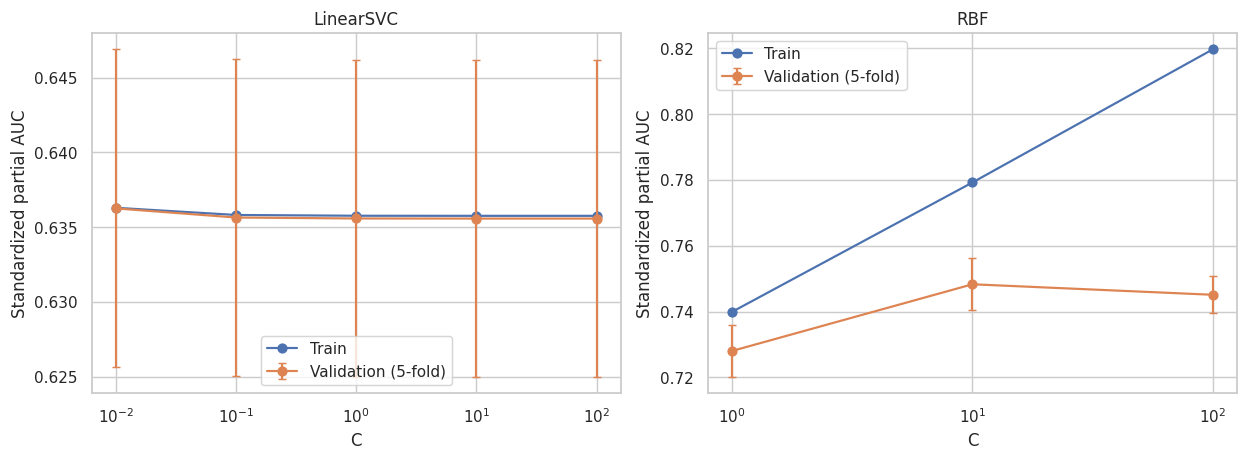

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (name, grid) in zip(axes, grids.items()):
    results = pd.DataFrame(grid.cv_results_)
    weight = grid.best_params_["svm__class_weight"]
    mask = results["param_svm__class_weight"].isna() if weight is None else (
        results["param_svm__class_weight"] == weight
    )
    if name == "RBF":
        mask &= results["param_svm__gamma"].astype(float) == grid.best_params_["svm__gamma"]
    subset = results.loc[mask].sort_values("param_svm__C")
    c_values = subset["param_svm__C"].astype(float)
    ax.plot(c_values, subset["mean_train_pauc"], "o-", label="Train")
    ax.errorbar(c_values, subset["mean_test_pauc"], yerr=subset["std_test_pauc"],
                fmt="o-", capsize=3, label="Validation (5-fold)")
    ax.set(xscale="log", xlabel="C", ylabel="Standardized partial AUC", title=name)
    ax.legend()

plt.tight_layout()
plt.savefig(output_dir / "train_validation.png", dpi=180)
plt.show()

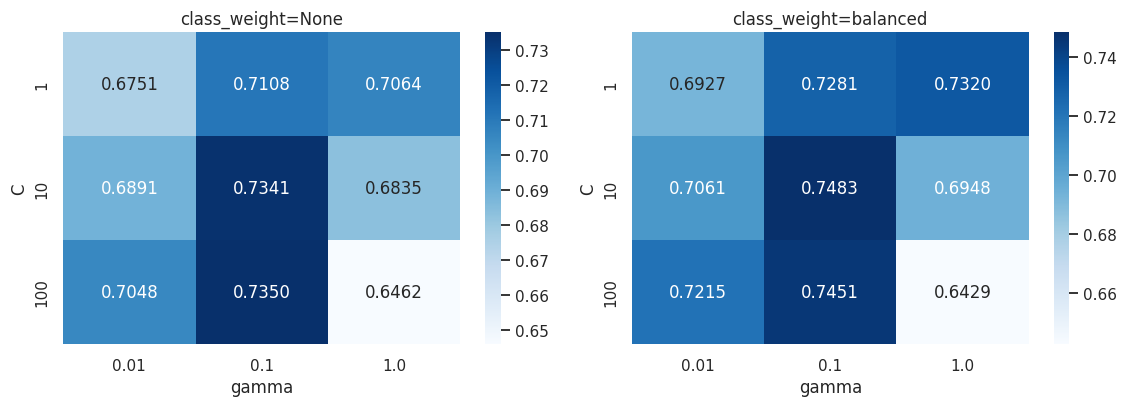

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, weight in zip(axes, [None, "balanced"]):
    mask = rbf_results["param_svm__class_weight"].isna() if weight is None else (
        rbf_results["param_svm__class_weight"] == weight
    )
    table = rbf_results.loc[mask].pivot(
        index="param_svm__C", columns="param_svm__gamma", values="mean_test_pauc"
    ).astype(float)
    sns.heatmap(table, annot=True, fmt=".4f", cmap="Blues", ax=ax)
    ax.set(title=f"class_weight={weight}", xlabel="gamma", ylabel="C")
plt.tight_layout()
plt.savefig(output_dir / "grid_rbf.png", dpi=180)
plt.show()

Model final dipilih berdasarkan rata-rata pAUC validasi tertinggi, **sebelum** melihat hasil test. Selanjutnya, skor out-of-fold model terpilih pada data latih digunakan untuk memilih threshold dengan recall gamma tertinggi di antara titik yang FPR-nya ≤5%. Ambang 5% adalah contoh target operasional yang ditetapkan sebelumnya.

Hyperparameter sudah dipilih dengan fold yang sama, sehingga hasil OOF untuk threshold masih bersifat pengembangan dan dapat optimistis. FPR ≤5% pada OOF tidak menjamin FPR test ≤5%, terlebih skor model hasil refit dapat berubah. Karena itu, threshold dibekukan dan baru dievaluasi pada data uji. Skor `decision_function` bukan probabilitas.

In [ ]:
from sklearn.model_selection import cross_val_predict

best_name = max(grids, key=lambda name: grids[name].best_score_)
best_model = grids[best_name].best_estimator_
print("Model final berdasarkan CV:", best_name)
print("Parameter:", grids[best_name].best_params_)

oof_scores = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="decision_function",
    n_jobs=N_JOBS, pre_dispatch=N_JOBS
)
fpr_oof, tpr_oof, thresholds_oof = roc_curve(y_train, oof_scores, drop_intermediate=False)
valid_indices = np.flatnonzero((fpr_oof <= 0.05) & np.isfinite(thresholds_oof))
best_index = valid_indices[np.argmax(tpr_oof[valid_indices])]
selected_threshold = float(thresholds_oof[best_index])
print("Threshold dari OOF:", selected_threshold)
print("FPR OOF:", fpr_oof[best_index])
print("Recall gamma OOF:", tpr_oof[best_index])

Model final berdasarkan CV: RBF
Parameter: {'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 0.1}
Threshold dari OOF: 1.1100406720111473
FPR OOF: 0.0498288322556105
Recall gamma OOF: 0.5738901277113319


Mulai sel berikut, test baru digunakan. RBF awal, LinearSVC terbaik, dan RBF terbaik dilaporkan bersama.

In [ ]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale", cache_size=256))
])
baseline_model.fit(X_train, y_train)
models = {
    "RBF awal": baseline_model,
    "LinearSVC": grids["LinearSVC"].best_estimator_,
    "RBF tuning": grids["RBF"].best_estimator_
}

test_rows = []
test_scores = {}
test_predictions = {}
for name, model in models.items():
    scores = model.decision_function(X_test)
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    test_scores[name] = scores
    test_predictions[name] = pred
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "ROC AUC": roc_auc_score(y_test, scores),
        "pAUC": roc_auc_score(y_test, scores, max_fpr=0.1),
        "Recall gamma": tp / (tp + fn),
        "FPR hadron": fp / (fp + tn)
    })

test_summary = pd.DataFrame(test_rows)
test_summary.to_csv(output_dir / "evaluasi_test.csv", index=False)
print("Accuracy baseline selalu gamma:", (y_test == 1).mean())
test_summary.round(4)

Accuracy baseline selalu gamma: 0.6522084104734197


,Model,Accuracy,Balanced accuracy,F1 macro,ROC AUC,pAUC,Recall gamma,FPR hadron
0,RBF awal,0.8715,0.8347,0.8505,0.9144,0.6974,0.9554,0.2859
1,LinearSVC,0.7823,0.7648,0.7623,0.8372,0.6274,0.8224,0.2928
2,RBF tuning,0.8670,0.8508,0.8526,0.9257,0.7467,0.9039,0.2023


In [ ]:
final_scores = best_model.decision_function(X_test)
default_pred = best_model.predict(X_test)
threshold_pred = (final_scores >= selected_threshold).astype(int)

threshold_rows = []
for name, pred in [("Default (0)", default_pred), ("Threshold OOF", threshold_pred)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "Aturan": name, "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy": accuracy_score(y_test, pred), "Precision gamma": tp / (tp + fp),
        "Recall gamma": tp / (tp + fn), "FPR hadron": fp / (fp + tn)
    })
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(output_dir / "evaluasi_threshold.csv", index=False)
threshold_table.round(4)

,Aturan,TN,FP,FN,TP,Accuracy,Precision gamma,Recall gamma,FPR hadron
0,Default (0),1049,266,237,2229,0.8670,0.8934,0.9039,0.2023
1,Threshold OOF,1245,70,1067,1399,0.6993,0.9523,0.5673,0.0532


In [ ]:
for name, pred in [("Default", default_pred), ("Threshold OOF", threshold_pred)]:
    print(name)
    print(classification_report(y_test, pred, labels=[0, 1],
                                target_names=["Hadron", "Gamma"], digits=4))
    report_df = pd.DataFrame(classification_report(
        y_test, pred, labels=[0, 1], target_names=["Hadron", "Gamma"], output_dict=True
    )).T
    report_df.to_csv(output_dir / f"classification_report_{name.replace(' ', '_')}.csv")

Default
              precision    recall  f1-score   support

      Hadron     0.8157    0.7977    0.8066      1315
       Gamma     0.8934    0.9039    0.8986      2466

    accuracy                         0.8670      3781
   macro avg     0.8545    0.8508    0.8526      3781
weighted avg     0.8664    0.8670    0.8666      3781

Threshold OOF
              precision    recall  f1-score   support

      Hadron     0.5385    0.9468    0.6865      1315
       Gamma     0.9523    0.5673    0.7111      2466

    accuracy                         0.6993      3781
   macro avg     0.7454    0.7570    0.6988      3781
weighted avg     0.8084    0.6993    0.7025      3781



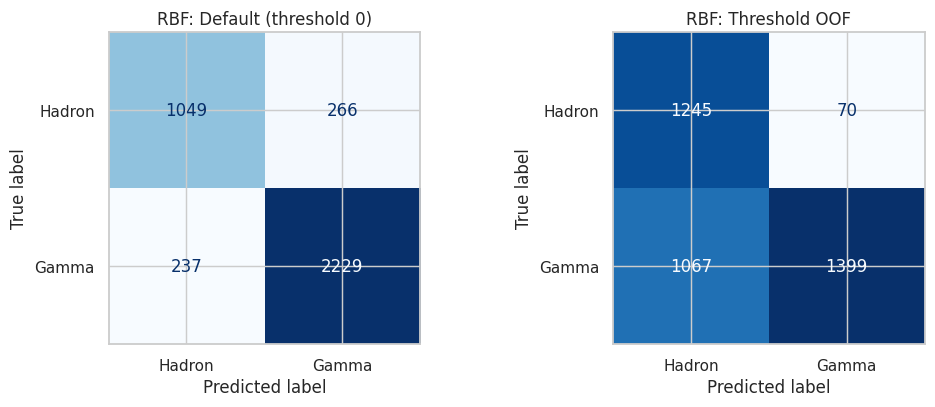

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, pred in zip(axes, ["Default (threshold 0)", "Threshold OOF"],
                          [default_pred, threshold_pred]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["Hadron", "Gamma"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"{best_name}: {name}")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix.png", dpi=180)
plt.show()

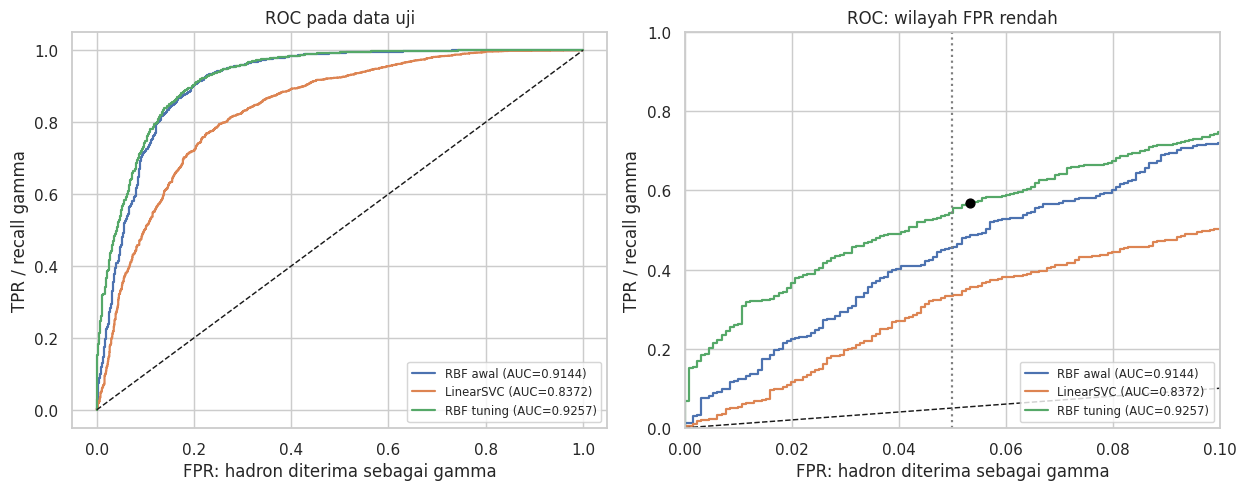

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    for ax in axes:
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")
for ax in axes:
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set(xlabel="FPR: hadron diterima sebagai gamma", ylabel="TPR / recall gamma")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_title("ROC pada data uji")
axes[1].set(xlim=(0, 0.1), ylim=(0, 1), title="ROC: wilayah FPR rendah")
axes[1].axvline(0.05, color="gray", linestyle=":")
axes[1].scatter(threshold_table.iloc[1]["FPR hadron"],
                threshold_table.iloc[1]["Recall gamma"], color="black", zorder=5)
plt.tight_layout()
plt.savefig(output_dir / "roc_test.png", dpi=180)
plt.show()

In [ ]:
comparison_table = pd.DataFrame({
    "y_true": y_test,
    "score": final_scores,
    "pred_default": default_pred,
    "pred_threshold_oof": threshold_pred
}, index=X_test.index)
comparison_table.to_csv(output_dir / "prediksi_test.csv", index_label="indeks_data_bersih")

summary = {
    "sklearn_version": sklearn.__version__,
    "n_raw": n_raw, "n_duplicates": n_duplicate, "n_clean": len(data_df),
    "n_train": len(X_train), "n_test": len(X_test),
    "best_model": best_name,
    "best_params": {name: grid.best_params_ for name, grid in grids.items()},
    "cv": cv_summary.to_dict(orient="records"),
    "scaling": scaling_table.to_dict(orient="records"),
    "test": test_summary.to_dict(orient="records"),
    "threshold": selected_threshold,
    "oof_fpr": float(fpr_oof[best_index]),
    "oof_tpr": float(tpr_oof[best_index]),
    "threshold_test": threshold_table.to_dict(orient="records"),
    "cv_fold_pauc": {
        name: [float(grid.cv_results_[f"split{i}_test_pauc"][grid.best_index_])
               for i in range(5)] for name, grid in grids.items()
    }
}
with open(output_dir / "ringkasan_hasil.json", "w") as file:
    json.dump(summary, file, indent=2)

print("Model final:", best_name)
print("Hasil tersimpan di:", output_dir.resolve())

Model final: RBF
Hasil tersimpan di: /workspace/scratch/db90ea066a4f/work/hasil_svm


In [ ]:
import shutil

shutil.make_archive("hasil_svm", "zip", output_dir)
# Hapus tanda # pada dua baris berikut untuk mengunduh dari Colab.
# from google.colab import files
# files.download("hasil_svm.zip")

'/workspace/scratch/db90ea066a4f/work/hasil_svm.zip'